# 06 · Robustness: held-out validation
Several earlier numbers were measured on the same payments that were used to build the rule (in-sample).
Here every rule is **learned on the earlier part of the period and tested on the later part**, which the rule has never seen.

* Train = payments before the cut-off date (first 2/3 of the 3-month window)
* Test  = payments after it (last 1/3)

Importing `utils` also runs the data integrity check: the notebook stops unless the data has exactly 10,000,000 rows.

In [12]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export, con
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [13]:
cut = q("SELECT quantile_disc(EPOCH_SECONDS, 2/3) c FROM f").c[0]
split = q(f'''SELECT EPOCH_SECONDS < {cut} AS is_train, count(*) n, min(TS_UTC) first_ts, max(TS_UTC) last_ts FROM f GROUP BY 1 ORDER BY 1 DESC''')
print('cut-off:', pd.to_datetime(cut, unit='s'), 'UTC'); split

cut-off: 2023-06-28 12:22:04 UTC


,is_train,n,first_ts,last_ts
0,True,6666665,2023-04-30 11:22:26,2023-06-28 12:22:03
1,False,3333335,2023-06-28 12:22:04,2023-07-31 09:56:01


## 1. Duration is decided by the bank pair — out of sample (replaces the in-sample 98.4%)
For each pair of banks, compute the mean log10(duration) on **train** payments only, then predict **test** payments.
R² on test = 1 − (squared error of the prediction) / (variance of test durations). Baseline: predicting every payment with the overall train mean (R² ≈ 0).

In [14]:
con.execute(f'''CREATE OR REPLACE TEMP TABLE hop AS
  SELECT ROW_ID, EPOCH_SECONDS < {cut} AS is_train, string_split(BIC8_PATH,';')[1] b1, string_split(BIC8_PATH,';')[2] b2,
         TOTAL_DURATION d, log10(TOTAL_DURATION) ld, ANOMALY
  FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP''')
ho = q('''WITH tr AS (SELECT b1, b2, avg(ld) m, count(*) c FROM hop WHERE is_train GROUP BY 1,2),
               gm AS (SELECT avg(ld) g FROM hop WHERE is_train),
               te AS (SELECT h.ld, tr.m, tr.c FROM hop h LEFT JOIN tr USING (b1,b2) WHERE NOT h.is_train)
          SELECT min_train AS min_train_payments_per_pair,
                 count(*) FILTER (c >= min_train) AS test_payments_covered,
                 count(*) FILTER (c >= min_train) / count(*) AS share_of_test_covered,
                 1 - sum(pow(ld-m,2)) FILTER (c >= min_train) / sum(pow(ld - avg_te,2)) FILTER (c >= min_train) AS r2_test_pair_mean,
                 1 - sum(pow(ld-g,2)) FILTER (c >= min_train) / sum(pow(ld - avg_te,2)) FILTER (c >= min_train) AS r2_test_global_mean,
                 avg((abs(ld-m) < log10(2))::int) FILTER (c >= min_train) AS share_within_factor_2
          FROM te, gm, (SELECT avg(ld) avg_te FROM te), (SELECT unnest([1,5,30]) AS min_train)
          GROUP BY 1 ORDER BY 1''')
export(ho,'validation_duration_pair_heldout'); ho

,min_train_payments_per_pair,test_payments_covered,share_of_test_covered,r2_test_pair_mean,r2_test_global_mean,share_within_factor_2
0,1,1850296,0.923830,0.981087,-0.000079,0.961167
1,5,1536936,0.767373,0.981989,-0.000171,0.965863
2,30,921952,0.460319,0.984103,0.000086,0.967954


Also with a **random** split inside each bank pair (every other payment), to check the result does not depend on time:

In [15]:
q('''WITH h AS (SELECT *, row_number() OVER (PARTITION BY b1,b2 ORDER BY ROW_ID) % 2 = 0 AS is_tr FROM hop),
          tr AS (SELECT b1,b2, avg(ld) m, count(*) c FROM h WHERE is_tr GROUP BY 1,2),
          te AS (SELECT h.ld, tr.m FROM h JOIN tr USING (b1,b2) WHERE NOT h.is_tr AND tr.c >= 5)
     SELECT count(*) test_payments, 1 - sum(pow(ld-m,2)) / (count(*)*var_pop(ld)) AS r2_test, avg((abs(ld-m) < log10(2))::int) AS share_within_factor_2 FROM te''')

,test_payments,r2_test,share_within_factor_2
0,2243932,0.981747,0.965547


## 2. One delay per bank, adding along the path — learned on train 2-bank payments, tested on test 3-bank payments
Both the period **and** the path length differ from the training data. We report two measures, as both matter:
correlation on the log scale (does the model rank payments correctly?) and the share predicted within a factor of 2 (is it accurate?).

In [16]:
pm = q('SELECT b1, b2, median(d) d, count(*) n FROM hop WHERE is_train GROUP BY ALL')
banks = pd.Index(pd.unique(pd.concat([pm.b1, pm.b2]))); t = pd.Series(pm.d.median()/2, index=banks)
c1 = pm.groupby('b1').n.sum().reindex(banks).fillna(0); c2 = pm.groupby('b2').n.sum().reindex(banks).fillna(0)
for it in range(25):
    a = pm.assign(r=pm.d - pm.b2.map(t).values, w=pm.n).groupby('b1').apply(lambda g: np.average(g.r, weights=g.w), include_groups=False).reindex(banks).fillna(0)
    b = pm.assign(r=pm.d - pm.b1.map(t).values, w=pm.n).groupby('b2').apply(lambda g: np.average(g.r, weights=g.w), include_groups=False).reindex(banks).fillna(0)
    t = ((a*c1 + b*c2) / (c1+c2)).clip(lower=1)
con.register('tb_train', t.rename('delay_s').rename_axis('bic').reset_index())
v = q(f'''WITH x AS (SELECT TOTAL_DURATION d, string_split(BIC8_PATH,';') bs, TRANSACTION_TYPE_CODE ty
                     FROM f WHERE PARTICIPANT_COUNT=3 AND NOT HAS_GAP AND EPOCH_SECONDS >= {cut})
          SELECT ty, count(*) n, corr(log10(d), log10(t1.delay_s+t2.delay_s+t3.delay_s)) AS corr_log,
                 avg((d BETWEEN 0.5*(t1.delay_s+t2.delay_s+t3.delay_s) AND 2*(t1.delay_s+t2.delay_s+t3.delay_s))::int) AS share_within_factor_2,
                 median(abs(log10(d) - log10(t1.delay_s+t2.delay_s+t3.delay_s))) AS median_abs_log10_error
          FROM x JOIN tb_train t1 ON t1.bic=bs[1] JOIN tb_train t2 ON t2.bic=bs[2] JOIN tb_train t3 ON t3.bic=bs[3] GROUP BY 1 ORDER BY 1''')
export(v,'validation_duration_additive_heldout'); v

,ty,n,corr_log,share_within_factor_2,median_abs_log10_error
0,Covered,78698,0.830516,0.499530,0.301631
1,Indirect,619906,0.931589,0.607271,0.190969


In [17]:
# where does the additive model miss? split test payments by predicted duration
q(f'''WITH x AS (SELECT TOTAL_DURATION d, string_split(BIC8_PATH,';') bs FROM f WHERE PARTICIPANT_COUNT=3 AND NOT HAS_GAP AND EPOCH_SECONDS >= {cut} AND TRANSACTION_TYPE_CODE='Indirect'),
          y AS (SELECT d, t1.delay_s+t2.delay_s+t3.delay_s p FROM x JOIN tb_train t1 ON t1.bic=bs[1] JOIN tb_train t2 ON t2.bic=bs[2] JOIN tb_train t3 ON t3.bic=bs[3])
     SELECT CASE WHEN p < 200 THEN '1 predicted < 200 s (fast banks only)' WHEN p < 1000 THEN '2 predicted 200-1000 s' ELSE '3 predicted > 1000 s (a slow bank on the path)' END AS segment,
            count(*) n, avg((d BETWEEN 0.5*p AND 2*p)::int) share_within_factor_2, median(d/p) median_actual_over_predicted
     FROM y GROUP BY 1 ORDER BY 1''')

,segment,n,share_within_factor_2,median_actual_over_predicted
0,1 predicted < 200 s (fast banks only),352009,0.343747,0.446519
1,2 predicted 200-1000 s,83949,0.851719,0.935197
2,3 predicted > 1000 s (a slow bank on the path),183948,1.000000,0.984056


## 3. Currency conversions — currency areas learned on train, tested on test
The earlier analysis inferred currency areas from conversion outcomes and checked them on the same payments (circular).
Here areas are learned from **train** direct payments only; the rule "a link converts iff it crosses an area border" is then scored on **test** payments,
first direct (one link), then 3–6-bank paths (several links, never used for learning).

In [18]:
import networkx as nx
tr = q(f'''SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2, count(*) n, avg(CURRENCY_CONVERSION_COUNT) p
           FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP AND EPOCH_SECONDS < {cut} AND substr(string_split(BIC8_PATH,';')[1],5,2) <> substr(string_split(BIC8_PATH,';')[2],5,2)
           GROUP BY 1,2 HAVING count(*) >= 100''')
G = nx.Graph(); G.add_edges_from(tr[tr.p < 0.02][['c1','c2']].itertuples(index=False))
zones = sorted([sorted(c) for c in nx.connected_components(G)], key=len, reverse=True)
for z in zones: print(len(z), z)
zt = pd.DataFrame([(c, i) for i, z in enumerate(zones) for c in z], columns=['country','zone']); con.register('zt', zt); con.register('tr', tr[['c1','c2']])

25 ['AD', 'AT', 'BE', 'CY', 'DE', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'IE', 'IT', 'LT', 'LU', 'LV', 'MC', 'MQ', 'MT', 'NL', 'PT', 'SI', 'SK', 'SM', 'XK']
8 ['BQ', 'EC', 'GU', 'PR', 'SV', 'TL', 'US', 'VG']
4 ['GB', 'GG', 'IM', 'JE']
2 ['CH', 'LI']


In [19]:
fxd = q(f'''WITH d AS (SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2, CURRENCY_CONVERSION_COUNT fx
                     FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP AND EPOCH_SECONDS >= {cut}),
               s AS (SELECT d.*, (coalesce('Z'||z1.zone::varchar, c1) = coalesce('Z'||z2.zone::varchar, c2)) AS same_area,
                            (c1||c2) IN (SELECT c1||c2 FROM tr) OR (c2||c1) IN (SELECT c1||c2 FROM tr) OR c1=c2 AS pair_seen_in_train
                     FROM d LEFT JOIN zt z1 ON z1.country=c1 LEFT JOIN zt z2 ON z2.country=c2)
          SELECT pair_seen_in_train, count(*) n, avg((fx = (NOT same_area)::int)::int) AS share_rule_correct, sum((fx <> (NOT same_area)::int)::int) AS exceptions,
                 avg((fx = 1)::int) FILTER (NOT same_area) AS converts_when_area_differs, avg((fx = 0)::int) FILTER (same_area) AS no_conversion_when_same_area
          FROM s GROUP BY 1 ORDER BY 1 DESC''')
export(fxd,'validation_fx_direct_heldout'); fxd

,pair_seen_in_train,n,share_rule_correct,exceptions,converts_when_area_differs,no_conversion_when_same_area
0,True,1893335,1.000000,0.0,1.000000,1.0
1,False,109519,0.995243,521.0,0.995101,1.0


In [20]:
fxl = q(f'''WITH t AS (SELECT ROW_ID, PARTICIPANT_COUNT k, CURRENCY_CONVERSION_COUNT fx, list_transform(string_split(BIC8_PATH,';'), lambda x: substr(x,5,2)) cs
                     FROM f WHERE NOT HAS_GAP AND PARTICIPANT_COUNT BETWEEN 3 AND 6 AND EPOCH_SECONDS >= {cut}),
               u AS (SELECT ROW_ID, k, fx, unnest(cs) c, generate_subscripts(cs,1) i FROM t),
               z AS (SELECT u.*, coalesce('Z'||zt.zone::varchar, c) area FROM u LEFT JOIN zt ON zt.country=u.c),
               w AS (SELECT ROW_ID, k, fx, area, lag(area) OVER (PARTITION BY ROW_ID ORDER BY i) prev FROM z),
               r AS (SELECT ROW_ID, any_value(k) k, any_value(fx) fx, sum((prev IS NOT NULL AND prev<>area)::int) crossings FROM w GROUP BY 1)
          SELECT k AS participants, count(*) n, avg((fx = crossings)::int) AS share_fx_equals_crossings FROM r GROUP BY 1 ORDER BY 1''')
export(fxl,'validation_fx_paths_heldout'); fxl

,participants,n,share_fx_equals_crossings
0,3,698724,0.999459
1,4,244475,0.999395
2,5,85269,0.999238
3,6,29916,0.999231


## 4. Summary for the dashboard

In [21]:
h5 = ho.set_index('min_train_payments_per_pair').loc[5]
fxl_all = (fxl.n*fxl.share_fx_equals_crossings).sum()/fxl.n.sum()
fx_seen, fx_unseen = fxd.set_index('pair_seen_in_train').loc[True], fxd.set_index('pair_seen_in_train').loc[False]
summ = pd.DataFrame([
  ['Duration: bank-pair mean (direct payments)', 'R² on test', h5.r2_test_pair_mean, h5.share_of_test_covered, int(h5.test_payments_covered), 'pairs with 5+ training payments'],
  ['Duration: bank-pair mean (direct payments)', 'share within a factor of 2', h5.share_within_factor_2, h5.share_of_test_covered, int(h5.test_payments_covered), 'pairs with 5+ training payments'],
  ['Duration: additive bank delays, Indirect 3-bank', 'log correlation', v.set_index('ty').corr_log['Indirect'], np.nan, int(v.set_index('ty').n['Indirect']), '3-bank Indirect, visible path, all 3 banks estimated'],
  ['Duration: additive bank delays, Indirect 3-bank', 'share within a factor of 2', v.set_index('ty').share_within_factor_2['Indirect'], np.nan, int(v.set_index('ty').n['Indirect']), '3-bank Indirect, visible path, all 3 banks estimated'],
  ['Duration: additive bank delays, Covered 3-bank', 'share within a factor of 2', v.set_index('ty').share_within_factor_2['Covered'], np.nan, int(v.set_index('ty').n['Covered']), '3-bank Covered, visible path, all 3 banks estimated'],
  ['FX: direct payments, country pair seen in training', 'share where rule is correct', fx_seen.share_rule_correct, np.nan, int(fx_seen.n), 'direct, visible path'],
  ['FX: direct payments, country pair NOT seen in training', 'share where rule is correct', fx_unseen.share_rule_correct, np.nan, int(fx_unseen.n), 'direct, visible path'],
  ['FX: 3-6-bank paths (never used for learning)', 'FX count = area crossings', fxl_all, np.nan, int(fxl.n.sum()), '3-6 banks, visible path'],
], columns=['rule','measure','held_out_value','coverage_of_eligible_test','test_payments','scope'])
export(summ,'validation_summary')
summ.assign(held_out_value=summ.held_out_value.map('{:.2%}'.format), coverage_of_eligible_test=summ.coverage_of_eligible_test.map(lambda x: '' if pd.isna(x) else f'{x:.1%}'))

,rule,measure,held_out_value,coverage_of_eligible_test,test_payments,scope
0,Duration: bank-pair mean (direct payments),R² on test,98.20%,76.7%,1536936,pairs with 5+ training payments
1,Duration: bank-pair mean (direct payments),share within a factor of 2,96.59%,76.7%,1536936,pairs with 5+ training payments
2,"Duration: additive bank delays, Indirect 3-bank",log correlation,93.16%,,619906,"3-bank Indirect, visible path, all 3 banks est..."
3,"Duration: additive bank delays, Indirect 3-bank",share within a factor of 2,60.73%,,619906,"3-bank Indirect, visible path, all 3 banks est..."
4,"Duration: additive bank delays, Covered 3-bank",share within a factor of 2,49.95%,,78698,"3-bank Covered, visible path, all 3 banks esti..."
5,"FX: direct payments, country pair seen in trai...",share where rule is correct,100.00%,,1893335,"direct, visible path"
6,"FX: direct payments, country pair NOT seen in ...",share where rule is correct,99.52%,,109519,"direct, visible path"
7,FX: 3-6-bank paths (never used for learning),FX count = area crossings,99.94%,,1058384,"3-6 banks, visible path"


Shares are shown in percent with two decimals so that near-perfect results (e.g. 99.52%) are not rounded up to 100%; for the FX rows the number of exceptions is printed too. The correlation is a coefficient, not a share, so it is shown as r. The bank-pair result applies only to test payments whose bank pair had 5+ training payments; that coverage is printed next to it.

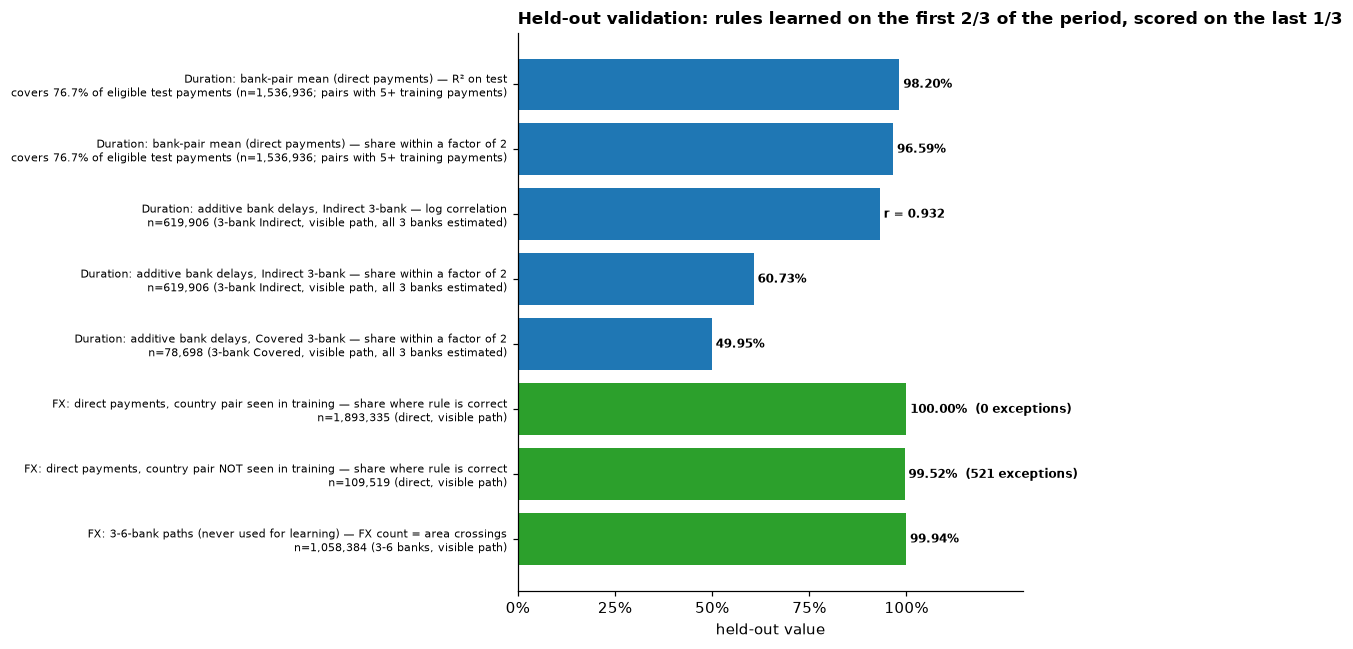

In [22]:
def pct(x): return f'{x:.2%}'
lab = []
for r in summ.itertuples():
    extra = f'\ncovers {r.coverage_of_eligible_test:.1%} of eligible test payments (n={r.test_payments:,}; {r.scope})' if pd.notna(r.coverage_of_eligible_test) else f'\nn={r.test_payments:,} ({r.scope})'
    lab.append(f'{r.rule} — {r.measure}{extra}')
fig, ax = plt.subplots(figsize=(9.5,6)); y = np.arange(len(summ))[::-1]
ax.barh(y, summ.held_out_value, color=['C0' if 'Duration' in r else 'C2' for r in summ.rule])
ax.set_xlim(0,1.3); ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=7)
exc = fxd.set_index('pair_seen_in_train').exceptions
def show(r):
    if r.measure == 'log correlation': return f'r = {r.held_out_value:.3f}'
    if r.rule.startswith('FX: direct payments, country pair seen'): return f'{pct(r.held_out_value)}  ({int(exc[True]):,} exceptions)'
    if r.rule.startswith('FX: direct payments, country pair NOT'): return f'{pct(r.held_out_value)}  ({int(exc[False]):,} exceptions)'
    return pct(r.held_out_value)
for yy, r in zip(y, summ.itertuples()): ax.text(r.held_out_value+.01, yy, show(r), va='center', fontsize=8, fontweight='bold')
ax.set_xticks([0,.25,.5,.75,1]); ax.set_xticklabels(['0%','25%','50%','75%','100%']); ax.set_xlabel('held-out value')
ax.set_title('Held-out validation: rules learned on the first 2/3 of the period, scored on the last 1/3')
savefig('F1_validation_summary')